In [1]:
import os
import pickle
import re
from utils import build_unique_name, load_experiment_results_from_config
from utils import oracle_len_pattern, create_patterns, quantile_with_nan, CI_length
import numpy as np
from utils import CustomScalarFormatter, moving_average

# For MCAR results

In [2]:
results = load_experiment_results_from_config(
    dataset_name='synthetic_linear',
    n_rep=500,
    train_size=500,
    cal_size=100,
    test_size_iid=2000,
    test_size_per_pattern=100,
    mechanism='MCAR',
    prob_missing=0.5,
    var_missing=[1]*10,
)

synthetic_linear_500_500_100_2000_100_MCAR_50.0_1111111111__


In [3]:
A = list(range(1023))

# Function to count the number of 1s in the binary representation
def count_ones(num):
    return bin(num).count('1')

# Sort indices of A based on the number of 1s in binary representation
sorted_indices = sorted(range(len(A)), key=lambda i: count_ones(A[i]))

In [4]:
d = 10
phi = 0.8
beta = np.array([1, 2, -1, 3, -0.5, -1, 0.3, 1.7, 0.4, -0.3])
cov = np.full((d,d),phi)+(1-phi)*np.eye(d)
alpha = 0.1

In [5]:
oracle_lent = []
for m in create_patterns(10,10):
    oracle_lent.append(oracle_len_pattern(m, beta, cov, alpha))
oracle_lent = np.array(oracle_lent)

In [6]:
compares = [
    'MDA-Exact',
    'MDA-Nested',
    'ARC CP',
    'Weighted CP',
]

/home/jfan/env/venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


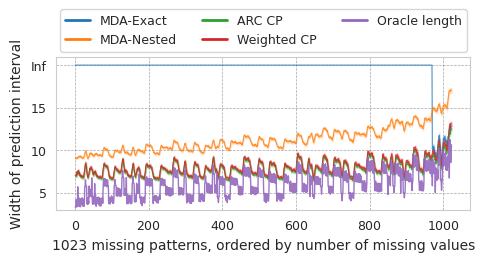

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_style("whitegrid")

window_size = 5
palette = sns.color_palette("tab10")
colors = palette.as_hex()

fig, axes = plt.subplots(figsize=(5, 3))

i = 0
lent_s = []
for k, key in enumerate(compares):
    table = results[k][0]
    
    cov = []
    cov_ci = []
    lent = []
    lent_ci = []
    for cln in table.columns:
        if cln.startswith('mask_cond_cov_num_mask_'):
            cov.append(table[cln].mean())
            cov_ci.append(CI_length(table[cln], 0.995))
        elif cln.startswith('mask_cond_cov_len_num_mask_'):
            lent.append(table[cln].mean())
            lent_ci.append(CI_length(table[cln], 0.995))
    
    lent = np.array(lent)[sorted_indices]
    lent_s.append(lent)
    lent = moving_average(lent, window_size)
    lent_ci = np.array(lent_ci)[sorted_indices]
    finite_lent = np.nan_to_num(lent, nan=20, posinf=20)

    cov = np.array(cov)[sorted_indices]
    
    cov_ci = np.array(cov_ci)[sorted_indices]
    
    x = np.arange(len(cov))
    
    plt.plot(x, finite_lent, label=f'{key}',
             linestyle='-', linewidth=0.8, alpha=0.8, color=colors[i])
    
    plt.fill_between(x, lent - lent_ci, 
                     lent + lent_ci, color=colors[i],
                     alpha=0.2)
    
    i += 1

plt.plot(x, oracle_lent[sorted_indices], label='Oracle length', color=colors[i], linewidth=1, alpha=0.9)

plt.xlabel('1023 missing patterns, ordered by number of missing values', fontsize=10)
plt.ylabel('Width of prediction interval', fontsize=10)
plt.ylim(3, 21)

ymajorformatter = CustomScalarFormatter(replace_values=([20], ['Inf']))
axes.yaxis.set_major_formatter(ymajorformatter)
plt.tick_params(axis='both', which='major', labelsize=9)

handles, labels = axes.get_legend_handles_labels()
new_handles = [plt.Line2D([], [], color=h.get_color(), linestyle=h.get_linestyle(), linewidth=2)
               for h in handles]

plt.legend(handles=new_handles, labels=labels, loc='upper center', 
           bbox_to_anchor=(0.5, 1.35), fontsize=9, ncol=3)
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()
plt.show()

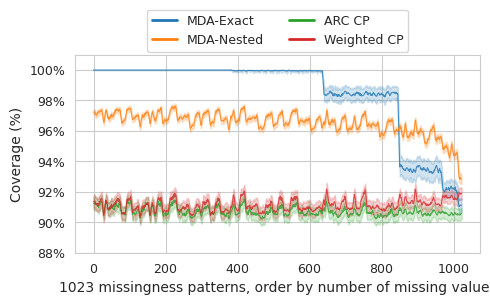

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import seaborn as sns
import numpy as np
sns.set_style("whitegrid")

window_size = 5
palette = sns.color_palette("tab10")
colors = palette.as_hex()

fig, axes = plt.subplots(figsize=(5,3.3))

i = 0

for k, key in enumerate(compares):
    table = results[k][0]
    
    cov = []
    cov_ci = []
    lent = []
    lent_ci = []
    for cln in table.columns:
        if cln.startswith('mask_cond_cov_num_mask_'):
            cov.append(table[cln].mean())
            cov_ci.append(CI_length(table[cln]))
        elif cln.startswith('mask_cond_cov_len_num_mask_'):
            lent.append(table[cln].mean())
            lent_ci.append(CI_length(table[cln]))
    
    cov = np.array(cov)[sorted_indices]
    cov = moving_average(cov, window_size)
    cov_ci = np.array(cov_ci)[sorted_indices]
    
    x = np.arange(len(cov))
    
    plt.plot(x, cov, label='{}'.format(key),
            linestyle='-', linewidth=0.8, alpha=0.8,color=colors[i])
    
    plt.fill_between(x, cov - cov_ci, 
                     np.minimum(cov + cov_ci,1),color=colors[i],
                     alpha=0.2)
    
    i += 1

plt.xlabel('1023 missingness patterns, order by number of missing values',fontsize=10)
plt.ylabel('Coverage (%)',fontsize=10)
plt.ylim(0.88, 1.01)
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ticks = [0.88, 0.90, 0.92, 0.94, 0.96, 0.98, 1.00]
plt.gca().set_yticks(ticks)
plt.gca().set_yticklabels([f'{int(tick * 100)}%' for tick in ticks])
plt.tick_params(axis='both', which='major', labelsize=9)
handles, labels = axes.get_legend_handles_labels()
new_handles = [plt.Line2D([], [], color=h.get_color(), linestyle=h.get_linestyle(), linewidth=2)
               for h in handles]

plt.legend(handles=new_handles, labels=labels, loc='upper center', 
           bbox_to_anchor=(0.5, 1.26), fontsize=9, ncol=2)

plt.grid(True)

plt.tight_layout()
plt.show()

# For MAR results

In [8]:
results = load_experiment_results_from_config(
    dataset_name='synthetic_linear',
    n_rep=100,
    train_size=500,
    cal_size=100,
    test_size_iid=2000,
    test_size_per_pattern=100,
    mechanism='MAR',
    prob_missing=0.2,
    var_missing=[0,0,0,0,0,1,1,1,1,1],
    data_folder='./results'
)

synthetic_linear_100_500_100_2000_100_MAR_20.0_0000011111__


In [9]:
for k, result in enumerate(results):
    if result is None:
        print("the results for {} is not done yet!".format(compares[k]))
    else:
        print(compares[k], "Marginal coverage: {:.4f}, marginal prediction interval width: {:.4f}, worst case coverage (95% CI): {:.4f}-{:.4f}".format(
            result[1]['marg_coverage'],
            result[1]['marg_cov_len'],
            result[1]['mask_cov_worst']-result[1]['mask_cov_worst_std']*1.96/10,
            result[1]['mask_cov_worst']+result[1]['mask_cov_worst_std']*1.96/10,
        ))


MDA-Exact Marginal coverage: 0.9148, marginal prediction interval width: 5.8481, worst case coverage (95% CI): 0.8786-0.8980
MDA-Nested Marginal coverage: 0.9125, marginal prediction interval width: 5.6656, worst case coverage (95% CI): 0.8785-0.8979
ARC CP Marginal coverage: 0.9055, marginal prediction interval width: 5.6395, worst case coverage (95% CI): 0.8842-0.9030
Weighted CP Marginal coverage: 0.9107, marginal prediction interval width: 5.8684, worst case coverage (95% CI): 0.8945-0.9131


# For MNAR results

In [10]:
results = load_experiment_results_from_config(
    dataset_name='synthetic_linear',
    n_rep=100,
    train_size=500,
    cal_size=100,
    test_size_iid=2000,
    test_size_per_pattern=100,
    mechanism='MNAR',
    prob_missing=0.2,
    var_missing=[0,0,0,0,0,1,1,1,1,1],
    data_folder='./results'
)

synthetic_linear_100_500_100_2000_100_MNAR_20.0_0000011111__


In [11]:
for k, result in enumerate(results):
    if result is None:
        print("the results for {} is not done yet!".format(compares[k]))
    else:
        print(compares[k], "Marginal coverage: {:.4f}, marginal prediction interval width: {:.4f}, worst case coverage (95% CI): {:.4f}-{:.4f}".format(
            result[1]['marg_coverage'],
            result[1]['marg_cov_len'],
            result[1]['mask_cov_worst']-result[1]['mask_cov_worst_std']*1.96/10,
            result[1]['mask_cov_worst']+result[1]['mask_cov_worst_std']*1.96/10,
        ))


MDA-Exact Marginal coverage: 0.9085, marginal prediction interval width: 5.7424, worst case coverage (95% CI): 0.8782-0.8972
MDA-Nested Marginal coverage: 0.9106, marginal prediction interval width: 5.6410, worst case coverage (95% CI): 0.8782-0.8972
ARC CP Marginal coverage: 0.9051, marginal prediction interval width: 5.6042, worst case coverage (95% CI): 0.8802-0.9002
Weighted CP Marginal coverage: 0.9104, marginal prediction interval width: 5.7787, worst case coverage (95% CI): 0.8912-0.9098
